# ALASKA2: from an independent holdout to a verified handoff

## Goal
Understand which evidence makes a steganalysis result and its saved artifacts reusable.

**MEASURED real-model result:** weighted AUC **0.83540** on the complete source-family holdout.
The retained checkpoint is a predeclared incomplete-run fallback. Quality and embedding-method
slices reveal limitations hidden by the pooled score.

This notebook reads the checked-in aggregate receipts, then **executes a synthetic CPU fixture
through the maintained package**. It does not retrain the real model, upload a submission, or claim
hosted Kaggle execution. [Results and scope](../docs/results.md).

## Setup
Use the locked Lab environment or `uv sync --locked --group lab --group analysis`. Competition
images and model weights are not needed for the default walkthrough. Real-model evidence was
obtained separately on P620 through the Docker GPU lane. All computation below that trains a model
is labeled `FIXTURE_NOT_A_MODEL_RESULT`.

In [1]:
import contextlib
import hashlib
import io
import json
import os
import tempfile
from pathlib import Path

from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = next(path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (path / "src/alaska2").is_dir() and (path / "pyproject.toml").is_file())
OUTPUTS = Path(os.environ.get("ALASKA2_OUTPUT_ROOT", str(ROOT.parent / (ROOT.name + "-outputs"))))
OUTPUTS.mkdir(parents=True, exist_ok=True)
source_paths = {"evaluation": ROOT / "evidence/phase2/retained_evaluation.json",
                "delivery": ROOT / "evidence/phase3/provenance_delivery.json",
                "split": ROOT / "evidence/phase1/split_audit.json"}
expected_digests = {
    "evaluation": "a73791b845001d0142878687de35638401b07fead8f80c466be8443b97f367ee",
    "delivery": "aaec5e0fc136435b606fba94b1aca0584bc7795e4387e545ed6cf575237a6221",
    "split": "d4cdb3f2a88cacca4962a09647bd8aef553d33209c543f774b2998d53771ed8d"
}
for name, path in source_paths.items():
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected_digests[name], "reviewed source changed"
evaluation, delivery, split = [
    json.loads(source_paths[name].read_text()) for name in ("evaluation", "delivery", "split")
]
assert evaluation["evaluation_verified"] and not evaluation["training_complete"]
print({"result_label": evaluation["result_label"], "holdout_rows": evaluation["membership"]["rows"],
       "weighted_auc": round(evaluation["metrics"]["pooled"]["weighted_auc"], 5)})

{'result_label': 'INCOMPLETE_REAL_DATA_BASELINE', 'holdout_rows': 60000, 'weighted_auc': 0.8354}


## Steps — what counts as an independent observation?
A Cover JPEG and its embedded variants share a source image. The original splitter already grouped
sources before expanding variants; the maintained package preserves that boundary and also rejects
byte-identical content across roles.

The counterfactual file-level split below measures exposure to shared content, **not a measured
increase in model score**. It motivates a grouping contract without inventing a model comparison.

In [2]:
diagnostic = split["row_level_diagnostic"]
assert split["families_in_multiple_folds"] == 0
pl.DataFrame(
    {
        "MEASURED diagnostic": [
            "Validation files",
            "Files with a sibling in training",
            "Families crossing retained folds",
        ],
        "Count": [
            diagnostic["valid_rows"],
            diagnostic["valid_rows_with_sibling_in_train"],
            split["families_in_multiple_folds"],
        ],
    }
)

MEASURED diagnostic,Count
str,i64
"""Validation files""",60000
"""Files with a sibling in traini…",59460
"""Families crossing retained fol…",0


## Evaluation judgment — inspect what the pooled metric hides
The fixed recipe asks whether its holdout score is broad across JPEG quality and embedding methods.
The measured slices answer that question more usefully than another unplanned backbone search.

Each quality cohort has the same number of families/files and class proportions. Different families
occupy those cohorts, so a quality gap does not isolate a causal compression effect. Method
comparisons share the same held-out families. The decision is to retain those slices and the fixed
checkpoint policy, rather than fit blend weights against this reported holdout.

In [3]:
analysis = evaluation["analysis"]
quality_rows = [
    {
        "Quality": quality,
        "Files": part["rows"],
        "Families": part["families"],
        "Weighted AUC": round(part["weighted_auc"], 5),
    }
    for quality, part in analysis["by_quality"].items()
]
pl.DataFrame(quality_rows)

Quality,Files,Families,Weighted AUC
str,i64,i64,f64
"""75""",20000,5000,0.86666
"""90""",20000,5000,0.84809
"""95""",20000,5000,0.76598


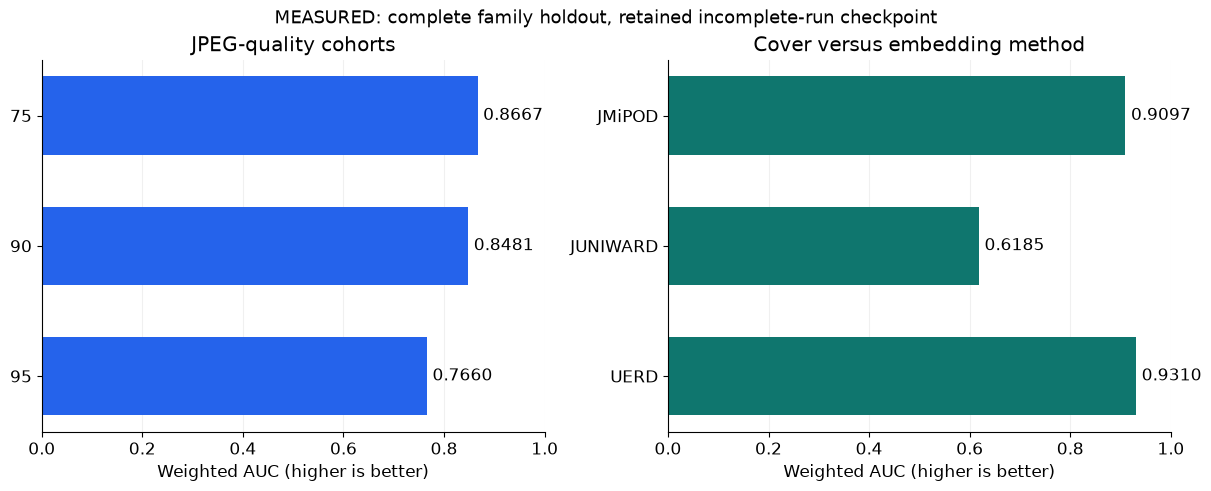

In [4]:
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, group, color, title in [
    (axes[0], analysis["by_quality"], "#2563eb", "JPEG-quality cohorts"),
    (axes[1], analysis["cover_vs_kind"], "#0f766e", "Cover versus embedding method"),
]:
    names = list(group)
    values = [group[name]["weighted_auc"] for name in names]
    bars = ax.barh(names, values, color=color, height=0.6)
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
    ax.set_xlabel("Weighted AUC (higher is better)")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.18)
    ax.set_axisbelow(True)
    ax.bar_label(bars, labels=[f"{value:.4f}" for value in values], padding=4)
fig.suptitle("MEASURED: complete family holdout, retained incomplete-run checkpoint", fontsize=13)
fig.savefig(OUTPUTS / "quality-and-method.png", dpi=150)
plt.show()

The quality-95 and JUNIWARD slices are weaker than the pooled score suggests. That observation does
not establish seed stability or performance on other acquisition domains.

The exact and legacy metric agree on these saved model predictions. The all-tied fixture below
exposes their known definition difference separately. A metric-fixture value is not a model result.

In [5]:
from alaska2.metrics import weighted_auc

labels = np.array([0, 1, 0, 1])
tied = weighted_auc(labels, np.zeros(len(labels)))
assert abs(tied - (2 * 0.32 + 0.18) / 1.4) < 1e-12
print({"FIXTURE_NOT_A_MODEL_RESULT": "all tied scores", "weighted_auc": round(tied, 6)})

{'FIXTURE_NOT_A_MODEL_RESULT': 'all tied scores', 'weighted_auc': 0.585714}


## Operational judgment — preserve valid computation across a failed handoff
The original training manifest remains interrupted. A successful continuation did not establish
completion; independent checkpoint reload later reconstructed the complete held-out and test
populations.

The controlled real-model filesystem drill then changed only the transfer failure condition. Local
scientific artifacts remained valid. A partial/corrupt transfer required explicit same-ID recovery
after the earlier importer stopped; changing the local journal could not replace destination
ownership. A rejected quality decision instead retained the research and required a model/policy
decision.

This supports separate training, evaluation and delivery states. It does not demonstrate a
production service or a remote MLflow/S3 transfer.

In [6]:
pl.DataFrame(
    [
        {
            "Controlled fault": row["fault"],
            "Treatment active": row["fault_active"],
            "Scientific artifacts unchanged": row["source_bundle_unchanged"],
            "Recovered transfer attempt": row["recovered"]["attempt"],
            "Same experiment identity": row["recovered"]["experiment_id"]
            == delivery["offline_bundle"]["experiment_id"],
        }
        for row in delivery["transfer_drills"]
    ]
)

Controlled fault,Treatment active,Scientific artifacts unchanged,Recovered transfer attempt,Same experiment identity
str,bool,bool,i64,bool
"""after_copy""",true,true,2,true
"""corrupt_copy""",true,true,2,true
"""after_publish""",true,true,2,true


## Checks — execute the maintained package on a CPU fixture
The artificial images below are generated at their native fixture size; the real JPEGs are not
resized. The fixture exercises training, evaluation, model reload, ordered CSV export and a
failed/recovered file transfer. Its score is **not** evidence about detecting embedded data in real
images.

In [7]:
from alaska2.composition import export_predictions
from alaska2.config import load_config
from alaska2.delivery import DeliveryError, create_bundle, deliver
from alaska2.evaluate import evaluate, verify
from alaska2.model import load_checkpoint
from alaska2.train import train
from tools.fixtures import build_fixture

with tempfile.TemporaryDirectory(prefix="alaska2-fixture-", dir=OUTPUTS) as folder:
    scratch = Path(folder)
    fixture = build_fixture(scratch / "data")
    cfg = load_config(ROOT / "configs/fixture_cpu.toml", [f'data.root="{fixture["root"]}"'])
    assert cfg["purpose"] == "fixture" and cfg["train"]["device"] == "cpu"
    with contextlib.redirect_stdout(io.StringIO()):
        run = train(cfg, run_dir=scratch / "run")
        checkpoint = run / "checkpoints/last.pt"
        valid = evaluate(checkpoint)
        valid_check = verify(valid)
        test = evaluate(checkpoint, split="test")
        test_check = verify(test)
    sample = scratch / "sample.csv"
    ids = pl.read_parquet(test)["image"].to_list()[::-1]
    pl.DataFrame({"Id": ids, "Label": [0] * len(ids)}).write_csv(sample)
    exported = export_predictions([test], [checkpoint], sample, scratch / "submission.csv")
    assert exported["result_label"] == "FIXTURE_NOT_A_MODEL_RESULT"
    weight_hash = load_checkpoint(checkpoint)["model_sha256"]
    identity = {
        "run_id": "cpu-walkthrough",
        "model_sha256": weight_hash,
        "result_label": exported["result_label"],
    }
    capsule = create_bundle(identity, {"model/checkpoint.pt": checkpoint}, scratch / "bundle")
    try:
        deliver(capsule, scratch / "destination", scratch / "events", fault="corrupt_copy")
    except DeliveryError:
        pass
    else:
        raise AssertionError("controlled corruption was not active")
    recovered = deliver(capsule, scratch / "destination", scratch / "events", recover=True)
    assert valid_check["passed"] and test_check["passed"] and recovered["attempt"] == 2
    fixture_summary = {
        "result_label": exported["result_label"],
        "holdout_rows": valid_check["rows"],
        "test_rows": test_check["rows"],
        "max_probability_delta": valid_check["observed"]["max_abs_prob_delta"],
        "csv_order_verified": exported["submission"]["id_order_verified"],
        "recovery_state": recovered["state"],
        "model_sha256": weight_hash,
    }
fixture_summary

{'result_label': 'FIXTURE_NOT_A_MODEL_RESULT',
 'holdout_rows': 16,
 'test_rows': 5,
 'max_probability_delta': 0.0,
 'csv_order_verified': True,
 'recovery_state': 'delivered',
 'model_sha256': 'a4e40c5f2f03dc532daaa91be9dc5789e9969ba570c53ff5f669af37ce174307'}

## Next steps and limits
The real-model result uses one family holdout and incomplete training. Its bootstrap percentiles
describe resampling that fixed holdout, not training-seed variance. Historical leaderboard scores
remain unrecovered. Learned stacking needs leakage-safe OOF inputs and a separate assessment; no
real ensemble gain is claimed.

The filesystem destination was verified; remote-service delivery and hosted Kaggle execution remain
unverified. The [reproduction guide](../docs/reproduction.md), [consumer
contract](../docs/consumer-contract.md) and [offline Kaggle guide](../docs/kaggle.md) retain those
boundaries. No additional model search is needed to reproduce this walkthrough.